# Data lake exploration — reading datasets 17-21 from the STAC catalog

Shows how to open each of the datasets published in the public STAC catalog (`gca-stac-7`) **using only the catalog**: no access to the P: drive is needed.

| # | Collection | Format | Read with |
|---|------------|--------|-----------|
| 17 | `seabed_lithology` | COG | `rasterio` |
| 18 | `hydrolakes` | GeoParquet | `geopandas` (bbox filter) |
| 19 | `country_boundaries` | GeoParquet | `geopandas` |
| 20 | `groundwater_recharge` | COG (2 items) | `rasterio` |
| 21 | `gebco` | COG (4 tiles) | `rasterio` (overviews / windows) |

Environment: `environment_exploration.yml` (Miniforge): `mamba env create -f environment_exploration.yml && conda activate gca-exploration`.

In [1]:
import time
from posixpath import join as urljoin

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
from rasterio.enums import Resampling
from rasterio.windows import Window

## 0) Open the catalog

The catalog is a static STAC on Google Cloud Storage. Public objects are cached for 1 h, so a query string forces a fresh copy of `catalog.json`. `get_collection()` can return another collection on a static catalog, so collections are matched by id.

In [2]:
gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
catalog = pystac_client.Client.open(f"{catalog_url}?nocache={time.time()}")


def get_items(collection_id: str) -> dict:
    """Return {item id: pystac.Item} for a collection of the catalog."""
    collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
    if collection is None:
        raise LookupError(f"Collection {collection_id} not found in {catalog_url}")
    items = {i.id: i for i in collection.get_items()}
    print(f"{collection.id} | {collection.title} | items: {list(items)}")
    return items


print("Collections in the catalog:", [c.id for c in catalog.get_children()])

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collections in the catalog: ['shore_mon_fut', 'sed_class', 'shore_mon', 'world_pop', 'world_gdp', 'shore_mon_hr', 'shore_mon_drivers', 'esl_gwl', 'sub_threat', 'SPMN', 'crop_production', 'crop_productivity_correction', 'salinity', 'salinity_increase', 'freshem_resistivity', 'freshem_chloride', 'seabed_lithology', 'hydrolakes', 'country_boundaries', 'groundwater_recharge', 'gebco']


## 17) Seabed lithology (COG)

One categorical raster. The `data` asset is a Cloud Optimized GeoTIFF: `rasterio` reads it directly from its URL.

seabed_lithology | Seafloor sediments in the world's ocean | items: ['seabed_litho.tif']
COG: https://storage.googleapis.com/gca-data-public/gca/seabed_lithology/seabed_litho.tif
Bbox: [-180.0, -90.0, 180.0, 90.0]
Raster bands: [{'nodata': -32768, 'data_type': 'int16', 'spatial_resolution': 0.1}]


c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


(1801, 3601) int16 EPSG:4326 nodata: -32768.0 overviews: [2, 4, 8]


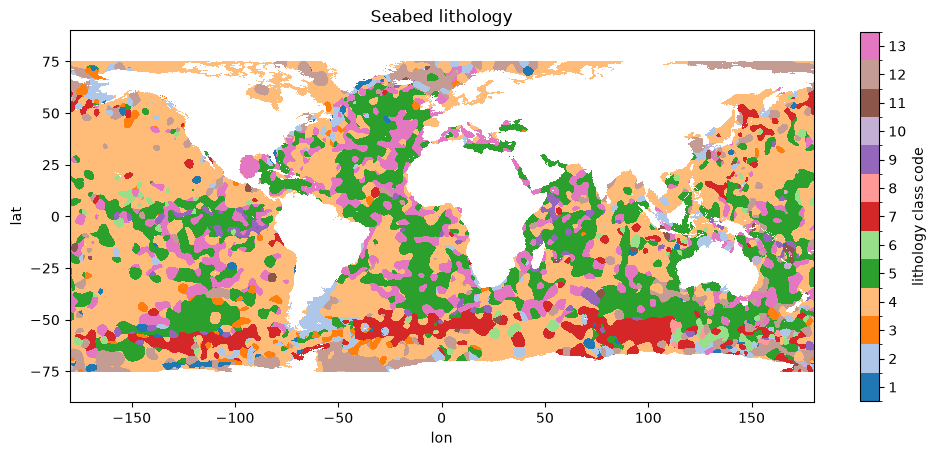

In [3]:
items = get_items("seabed_lithology")
item = next(iter(items.values()))
href = item.assets["data"].href
print("COG:", href)
print("Bbox:", item.bbox)
print("Raster bands:", item.assets["data"].extra_fields.get("raster:bands"))

with rasterio.open(href) as src:
    print(src.shape, src.dtypes[0], src.crs, "nodata:", src.nodata, "overviews:", src.overviews(1))
    litho = src.read(1)
    litho_nodata, litho_bounds = src.nodata, src.bounds

classes = np.unique(litho)
classes = classes[classes != litho_nodata]
cmap = ListedColormap(plt.get_cmap("tab20").colors[: len(classes)])
norm = BoundaryNorm(np.append(classes, classes.max() + 1) - 0.5, cmap.N)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(
    np.ma.masked_equal(litho, litho_nodata), cmap=cmap, norm=norm, interpolation="nearest",
    extent=(litho_bounds.left, litho_bounds.right, litho_bounds.bottom, litho_bounds.top),
)
fig.colorbar(im, ax=ax, ticks=classes, label="lithology class code", shrink=0.8)
ax.set_title("Seabed lithology")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

## 18) HydroLAKES (GeoParquet)

1.4 million lake polygons. Reading everything is slow, so only the polygons inside a bounding box are read: the GeoParquet file has a `bbox` covering column that lets `geopandas` skip the rest. Columns can also be selected with `pyarrow`.

hydrolakes | HydroLAKES | items: ['hydrolakes']
GeoParquet: https://storage.googleapis.com/gca-data-public/gca/hydrolakes/hydrolakes.parquet
Bbox: [-180.0, -55.865139, 180.0, 83.575951] | rows: 1427688
18 lakes in BBOX | crs: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipso

,Hylak_id,Lake_name,Country,Continent,Poly_src,Lake_type,Grand_id,Lake_area,Shore_len,Shore_dev,...,Vol_res,Vol_src,Depth_avg,Dis_avg,Res_time,Elevation,Slope_100,Wshd_area,Pour_long,Pour_lat
0,1492,Toshka 2,Egypt,Africa,SWBD,1,0,496.62,278.12,3.52,...,0.0,1,10.3,0.000,-1.0,132,1.47,16066.3,30.568750,23.460417
1,1494,NaN,Egypt,Africa,SWBD,1,0,355.72,270.12,4.04,...,0.0,3,7.5,0.000,-1.0,144,1.12,13309.9,30.635465,23.209324
2,1495,Toshka 1,Egypt,Africa,SWBD,1,0,542.80,333.30,4.04,...,0.0,1,23.0,0.000,-1.0,156,-1.00,6294.4,31.070019,23.056554
3,1388616,NaN,Egypt,Africa,SWBD,1,0,0.34,4.17,2.03,...,0.0,3,1.6,0.000,-1.0,158,0.43,5.9,31.235517,23.039316
4,152,Nasser,Egypt,Africa,SWBD,2,4478,5385.34,7201.04,27.68,...,162000.0,2,30.1,2669.791,702.3,179,-1.00,2764126.0,32.886458,23.967280


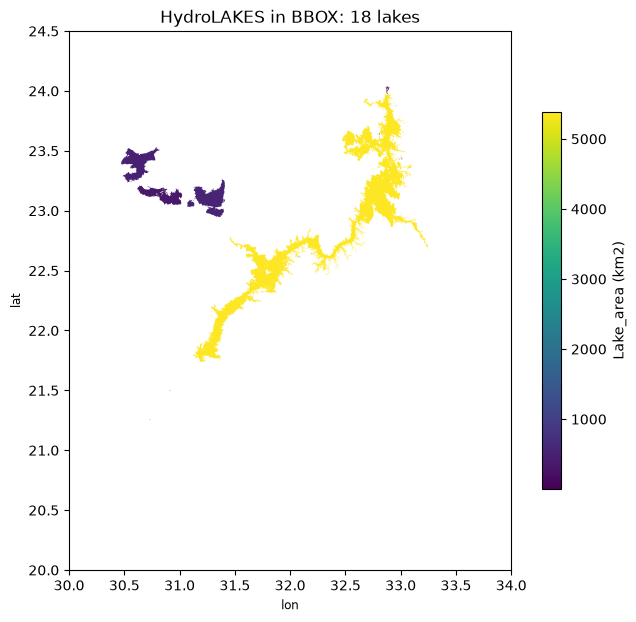

In [4]:
items = get_items("hydrolakes")
item = next(iter(items.values()))
href = item.assets["data"].href
print("GeoParquet:", href)
print("Bbox:", item.bbox, "| rows:", item.properties.get("table:row_count"))

# Region (west, south, east, north): Lake Nasser, Egypt/Sudan
BBOX = (30.0, 20.0, 34.0, 24.5)
lakes = gpd.read_parquet(href, bbox=BBOX, filesystem=fsspec.filesystem("https"))
lakes = lakes.drop(columns="bbox", errors="ignore")
print(f"{len(lakes)} lakes in BBOX | crs: {lakes.crs}")
display(lakes.drop(columns="geometry").head())

fig, ax = plt.subplots(figsize=(8, 7))
lakes.plot(ax=ax, column="Lake_area", cmap="viridis", legend=True, legend_kwds={"label": "Lake_area (km2)", "shrink": 0.7})
ax.set_xlim(BBOX[0], BBOX[2]); ax.set_ylim(BBOX[1], BBOX[3])
ax.set_title(f"HydroLAKES in BBOX: {len(lakes)} lakes")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

## 19) Country boundaries (GeoParquet)

Small layer (258 polygons): read completely. The file is downloaded with `requests` and parsed from memory.

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


country_boundaries | Admin 0 – Countries | items: ['country_boundaries']
GeoParquet: https://storage.googleapis.com/gca-data-public/gca/country_boundaries/country_boundaries.parquet
258 countries, 169 columns | crs: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "ax

,NE_ID,NAME,CONTINENT,POP_EST
0,1159320335,Antarctica,Antarctica,4490.0
1,1159320731,S. Geo. and the Is.,Seven seas (open ocean),30.0
2,1159320711,Falkland Is.,South America,3398.0
3,1729635141,Southern Patagonian Ice Field,South America,0.0
4,1159320493,Chile,South America,18952038.0


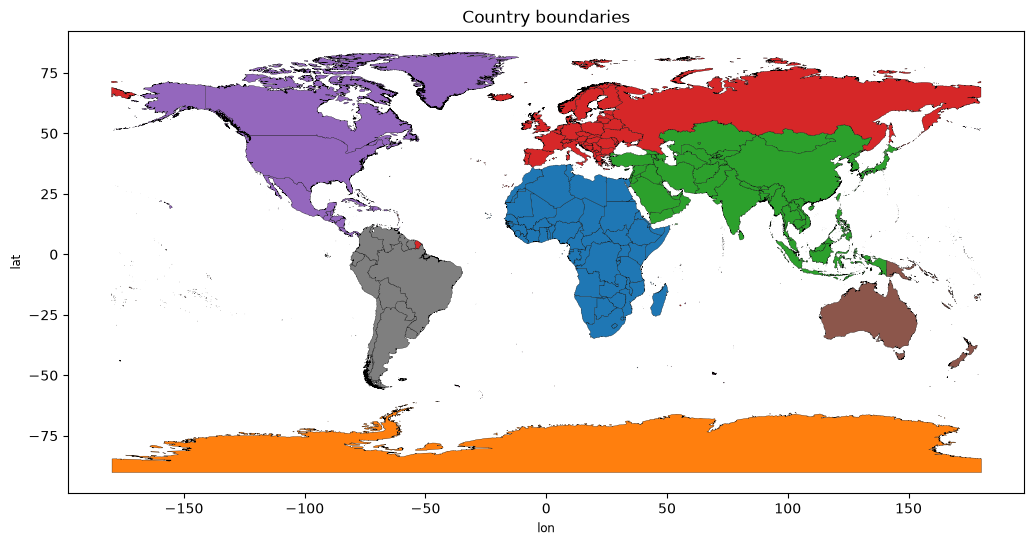

In [5]:
import io
import requests

items = get_items("country_boundaries")
item = next(iter(items.values()))
href = item.assets["data"].href
print("GeoParquet:", href)

resp = requests.get(href, timeout=120)
resp.raise_for_status()
countries = gpd.read_parquet(io.BytesIO(resp.content)).drop(columns="bbox", errors="ignore")
print(f"{len(countries)} countries, {len(countries.columns)} columns | crs: {countries.crs}")
display(countries[["NE_ID", "NAME", "CONTINENT", "POP_EST"]].head())

fig, ax = plt.subplots(figsize=(14, 6))
countries.plot(ax=ax, column="CONTINENT", cmap="tab10", edgecolor="black", linewidth=0.2)
ax.set_title("Country boundaries")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

## 20) Groundwater recharge (COG, two items)

One item per model (`RF_recharge_01`, `RF_RK_recharge_01`). Nodata is `-9999`; it is masked before plotting.

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


groundwater_recharge | Groundwater Recharge in Africa from Ground Based Measurements | items: ['RF_recharge_01', 'RF_RK_recharge_01']
RF_recharge_01: model RF | https://storage.googleapis.com/gca-data-public/gca/groundwater_recharge/RF_recharge_01.tif
    (721, 888) float32 EPSG:4326 | valid pixels: 252509
RF_RK_recharge_01: model RF_RK | https://storage.googleapis.com/gca-data-public/gca/groundwater_recharge/RF_RK_recharge_01.tif
    (721, 888) float32 EPSG:4326 | valid pixels: 252509


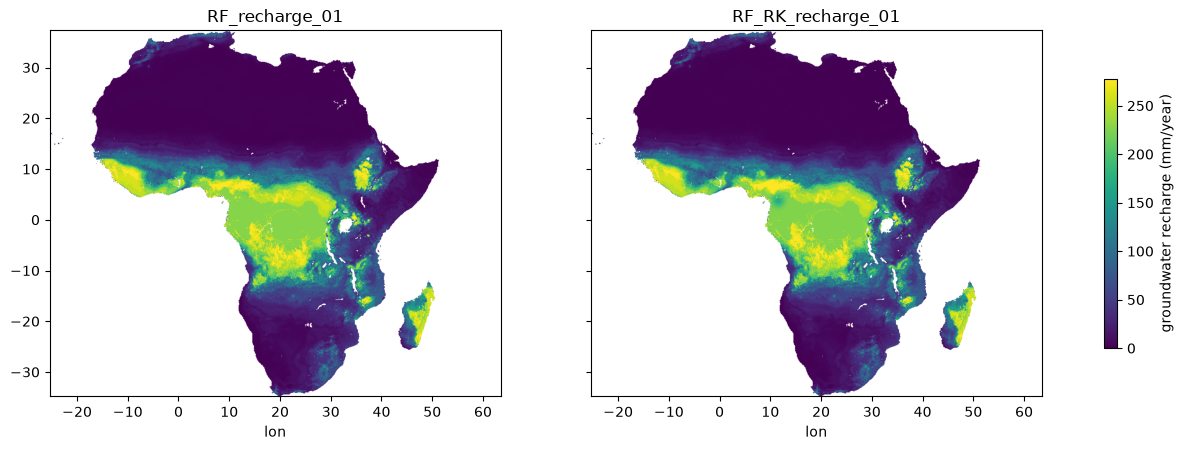

In [6]:
items = get_items("groundwater_recharge")

recharge, extents = {}, {}
for item_id, item in items.items():
    href = item.assets["data"].href
    print(f"{item_id}: model {item.properties.get('recharge:model')} | {href}")
    with rasterio.open(href) as src:
        data = src.read(1).astype("float64")
        valid = np.isfinite(data)
        if src.nodata is not None:
            valid &= ~np.isclose(data, src.nodata)
        recharge[item_id] = np.where(valid, data, np.nan)
        extents[item_id] = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
        print("   ", src.shape, src.dtypes[0], src.crs, "| valid pixels:", int(valid.sum()))

vmax = float(np.nanpercentile(np.concatenate([a[~np.isnan(a)] for a in recharge.values()]), 99))
fig, axes = plt.subplots(1, len(recharge), figsize=(8 * len(recharge), 5), sharex=True, sharey=True)
for ax, (item_id, arr) in zip(np.atleast_1d(axes), recharge.items()):
    im = ax.imshow(arr, cmap="viridis", vmin=0, vmax=vmax, extent=extents[item_id])
    ax.set_title(item_id)
    ax.set_xlabel("lon")
fig.colorbar(im, ax=axes, label="groundwater recharge (mm/year)", shrink=0.7)
plt.show()

## 21) GEBCO 2025 (COG, four tiles)

Each tile is 21600 x 21600 pixels, so it is **not** read completely:
- a decimated read (`out_shape`) uses the COG overviews and only downloads what is needed for an overview plot;
- a `Window` reads a small area at full resolution.

gebco | General Bathymetric Chart of the Oceans (GEBCO 2025 Grid) | items: ['gebco_2025_sub_ice_n0_s-90_w-90_e0', 'gebco_2025_sub_ice_n0_s-90_w0_e90', 'gebco_2025_sub_ice_n90_s0_w-90_e0', 'gebco_2025_sub_ice_n90_s0_w0_e90']
gebco_2025_sub_ice_n0_s-90_w-90_e0: (21600, 21600) int16 crs=EPSG:4326 nodata=-32767.0 bbox=[-90.0, -90.0, 0.0, 0.0]
gebco_2025_sub_ice_n0_s-90_w0_e90: (21600, 21600) int16 crs=EPSG:4326 nodata=-32767.0 bbox=[-0.0, -90.0, 90.0, 0.0]
gebco_2025_sub_ice_n90_s0_w-90_e0: (21600, 21600) int16 crs=EPSG:4326 nodata=-32767.0 bbox=[-90.0, 0.0, 0.0, 90.0]
gebco_2025_sub_ice_n90_s0_w0_e90: (21600, 21600) int16 crs=EPSG:4326 nodata=-32767.0 bbox=[-0.0, 0.0, 90.0, 90.0]


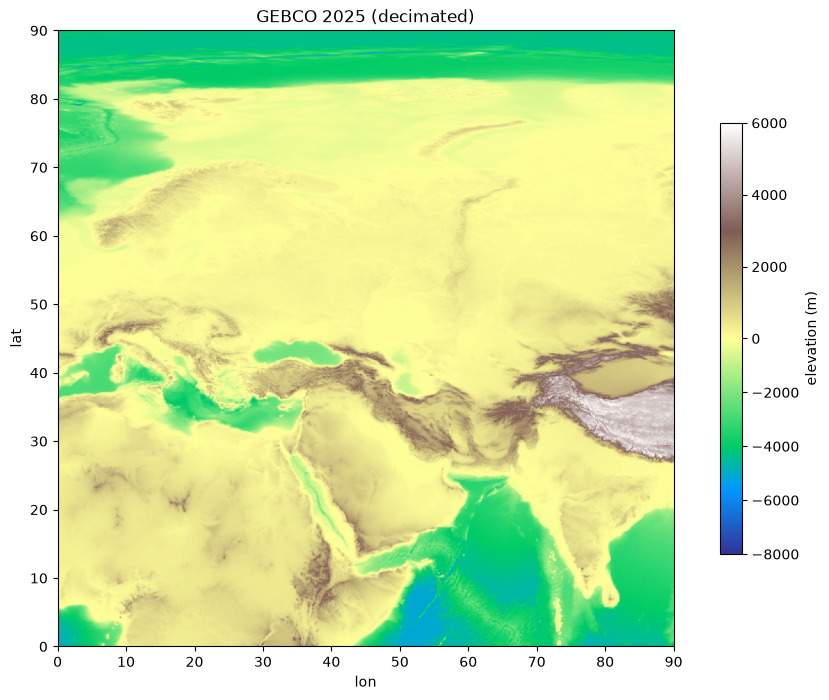

In [7]:
items = get_items("gebco")
DECIMATE = 20  # 21600 / 20 = 1080 pixels per tile

previews, extents = {}, {}
for item_id, item in items.items():
    href = item.assets["data"].href
    with rasterio.open(href) as src:
        previews[item_id] = src.read(
            1, out_shape=(src.height // DECIMATE, src.width // DECIMATE), resampling=Resampling.nearest
        )
        extents[item_id] = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
        print(f"{item_id}: {src.shape} {src.dtypes[0]} crs={src.crs} nodata={src.nodata} bbox={item.bbox}")

norm = TwoSlopeNorm(vmin=-8000, vcenter=0, vmax=6000)
fig, ax = plt.subplots(figsize=(12, 8))
for item_id, arr in previews.items():
    im = ax.imshow(np.ma.masked_equal(arr, -32767), cmap="terrain", norm=norm, extent=extents[item_id])
fig.colorbar(im, ax=ax, label="elevation (m)", shrink=0.7)
ax.set_title("GEBCO 2025 (decimated)")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

Full-resolution read of a small area (Nile delta, 1024 x 1024 pixels). The tile that contains the point is found from the item bboxes.

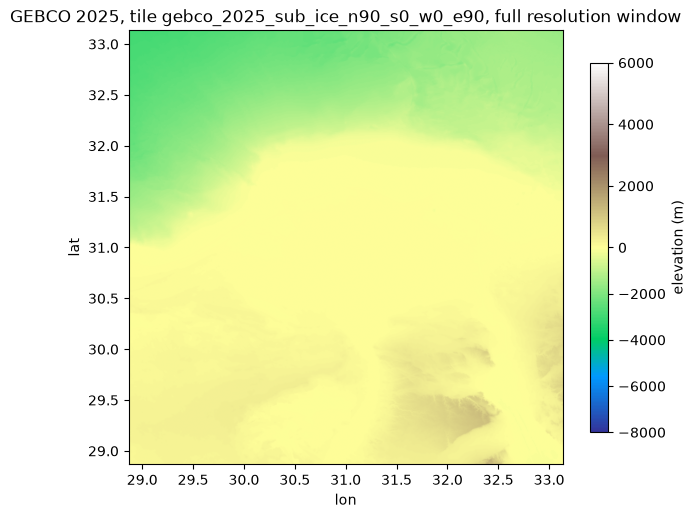

In [8]:
lon, lat = 31.0, 31.0
tile_id = next(i for i, it in items.items() if it.bbox[0] <= lon <= it.bbox[2] and it.bbox[1] <= lat <= it.bbox[3])

with rasterio.open(items[tile_id].assets["data"].href) as src:
    row, col = src.index(lon, lat)
    window = Window(col - 512, row - 512, 1024, 1024)
    chunk = src.read(1, window=window)
    b = src.window_bounds(window)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(chunk, cmap="terrain", norm=norm, extent=(b[0], b[2], b[1], b[3]))
fig.colorbar(im, ax=ax, label="elevation (m)", shrink=0.8)
ax.set_title(f"GEBCO 2025, tile {tile_id}, full resolution window")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()